In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# per 100k
x = [1.37, 2.74, 4.24, 5.74, 9.79, 11.1, 14.5, 30]
SR = [32.0, 40.5, 47.7, 49.6, 52.6, 53.7, 55.5, 58.6]
OSR = [44.5, 51.5, 57.4, 59.0, 61.9, 60.9, 63.2, 65.6]
SPL = [27.6, 35.5, 41.5, 43.4, 47.1, 47.0, 49.6, 52.3]
NE  = [7.86, 6.99, 5.72, 5.63, 5.29, 5.25, 4.90, 4.625]
# 创建画布
# 颜色方案
colors = {
    "SR": "#E64B35",   # 鲜红橙
    "OSR": "#4DBBD5",  # 亮蓝青
    "SPL": "#00A087",  # 绿青
    "NE": "#3C5488"    # 深蓝紫
}
def mix_colors(hex_list):
    rgb = np.mean([tuple(int(h[i:i+2], 16) for i in (1, 3, 5)) for h in hex_list], axis=0)
    return '#%02x%02x%02x' % tuple(int(v) for v in rgb)

mix_color = mix_colors([colors["SR"], colors["OSR"], colors["SPL"]])
# 创建画布
fig, ax1 = plt.subplots(figsize=(8, 4))

# 左侧纵轴（SR类）
ax1.set_xlabel('Data scale (100k)', fontsize=12)
ax1.set_ylabel('SR/OSR/SPL (%)', color=mix_color, fontsize=12)
l1, = ax1.plot(x, SR, marker='o', color=colors["SR"], label='SR', linewidth=2)
l2, = ax1.plot(x, OSR, marker='o', color=colors["OSR"], label='OSR', linewidth=2)
l3, = ax1.plot(x, SPL, marker='o', color=colors["SPL"], label='SPL', linewidth=2)

# 标注每个点的数值（左轴）
for idx, (xi, a, b, c) in enumerate(zip(x, SR, OSR, SPL)):
    if idx in [1,2]:
        if idx == 2:
            ax1.text(xi-0.9, a - 1.2, f'{a:.1f}', color=colors["SR"], fontsize=9, ha='center')
            ax1.text(xi-0.2, b + 0.8, f'{b:.1f}', color=colors["OSR"], fontsize=9, ha='center')
        else:
            ax1.text(xi-0.4, a + 1.2, f'{a:.1f}', color=colors["SR"], fontsize=9, ha='center')
            ax1.text(xi-0.4, b + 0.8, f'{b:.1f}', color=colors["OSR"], fontsize=9, ha='center')
        ax1.text(xi-0.4, c + 0.8, f'{c:.1f}', color=colors["SPL"], fontsize=9, ha='center')
    else:
        ax1.text(xi, a + 1.2, f'{a:.1f}', color=colors["SR"], fontsize=9, ha='center')
        ax1.text(xi, b + 1.2, f'{b:.1f}', color=colors["OSR"], fontsize=9, ha='center')
        ax1.text(xi, c + 1.2, f'{c:.1f}', color=colors["SPL"], fontsize=9, ha='center')

# 右侧纵轴（NE）
ax2 = ax1.twinx()
ax2.set_ylabel('NE (m)', color=colors["NE"], fontsize=12)
l4, = ax2.plot(x, NE, marker='o', color=colors["NE"], label='NE', linewidth=2, linestyle='--')

# 标注右轴的数值
for idx, (xi, n) in enumerate(zip(x, NE)):
    if idx in [1]:
        ax2.text(xi-1, n, f'{n:.2f}', color=colors["NE"], fontsize=9, ha='center')
    elif idx in [2]:
        ax2.text(xi+1.5, n, f'{n:.2f}', color=colors["NE"], fontsize=9, ha='center')
    else:
        ax2.text(xi, n + 0.1, f'{n:.2f}', color=colors["NE"], fontsize=9, ha='center')

# 设置纵轴范围
ax1.set_ylim(25, 70)
ax2.set_ylim(4.5, 8.5)

# 图例
lines = [l1, l2, l3, l4]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=False, bbox_to_anchor=(0.8, 0.4))

# 网格与布局
ax1.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig("./fig/performance-data_scale.pdf", format="pdf", dpi=200, bbox_inches='tight')
plt.show()

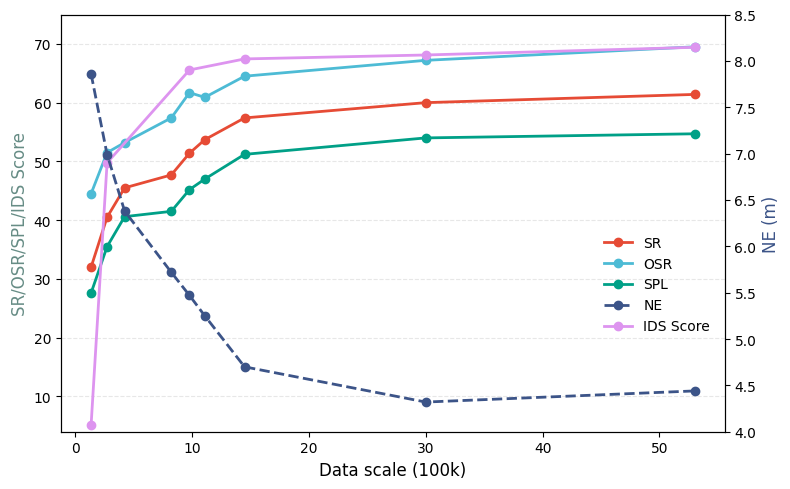

In [12]:
import matplotlib.pyplot as plt
import numpy as np
# per 100k
x = [1.37, 2.74, 4.24, 8.23, 9.79, 11.1, 14.5, 30, 53]
SR = [32.0, 40.5, 45.5, 47.7, 51.4, 53.7, 57.4, 60.0, 61.4]
OSR = [44.5, 51.5, 53.2, 57.4, 61.7, 60.9, 64.5, 67.2, 69.5]
SPL = [27.6, 35.5, 40.6, 41.5, 45.2, 47.0, 51.2, 54.0, 54.7]
NE  = [7.86, 6.99, 6.38, 5.72, 5.47, 5.25, 4.70, 4.32, 4.44]

idm_x = [1.37, 2.74, 9.79, 14.5, 30, 53]
idm_score = [5.09, 49.76, 65.56, 67.44, 68.11, 69.42]

colors = {
    "SR": "#E64B35",   # 鲜红橙
    "OSR": "#4DBBD5",  # 亮蓝青
    "SPL": "#00A087",  # 绿青
    "NE": "#3C5488",    # 深蓝紫
    "IDM":"#DD94EF"
}
def mix_colors(hex_list):
    rgb = np.mean([tuple(int(h[i:i+2], 16) for i in (1, 3, 5)) for h in hex_list], axis=0)
    return '#%02x%02x%02x' % tuple(int(v) for v in rgb)

mix_color = mix_colors([colors["SR"], colors["OSR"], colors["SPL"]])
# 创建画布
fig, ax1 = plt.subplots(figsize=(8, 5))

# 左侧纵轴（SR类）
ax1.set_xlabel('Data scale (100k)', fontsize=12)
ax1.set_ylabel('SR/OSR/SPL/IDS Score', color=mix_color, fontsize=12)
l1, = ax1.plot(x, SR, marker='o', color=colors["SR"], label='SR', linewidth=2)
l2, = ax1.plot(x, OSR, marker='o', color=colors["OSR"], label='OSR', linewidth=2)
l3, = ax1.plot(x, SPL, marker='o', color=colors["SPL"], label='SPL', linewidth=2)

# 标注每个点的数值（左轴）
# for idx, (xi, a, b, c) in enumerate(zip(x, SR, OSR, SPL)):
#     if idx in [1,2]:
#         if idx == 2:
#             ax1.text(xi-0.9, a - 1.2, f'{a:.1f}', color=colors["SR"], fontsize=9, ha='center')
#             ax1.text(xi-0.2, b + 0.8, f'{b:.1f}', color=colors["OSR"], fontsize=9, ha='center')
#         else:
#             ax1.text(xi-0.4, a + 1.2, f'{a:.1f}', color=colors["SR"], fontsize=9, ha='center')
#             ax1.text(xi-0.4, b + 0.8, f'{b:.1f}', color=colors["OSR"], fontsize=9, ha='center')
#         ax1.text(xi-0.4, c + 0.8, f'{c:.1f}', color=colors["SPL"], fontsize=9, ha='center')
#     else:
#         ax1.text(xi, a + 1.2, f'{a:.1f}', color=colors["SR"], fontsize=9, ha='center')
#         ax1.text(xi, b + 1.2, f'{b:.1f}', color=colors["OSR"], fontsize=9, ha='center')
#         ax1.text(xi, c + 1.2, f'{c:.1f}', color=colors["SPL"], fontsize=9, ha='center')

# 右侧纵轴（NE）
ax2 = ax1.twinx()
ax2.set_ylabel('NE (m)', color=colors["NE"], fontsize=12)
l4, = ax2.plot(x, NE, marker='o', color=colors["NE"], label='NE', linewidth=2, linestyle='--')


l5, = ax1.plot(idm_x, idm_score, marker='o', color=colors["IDM"], label='IDS Score', linewidth=2)

# 标注右轴的数值
# for idx, (xi, n) in enumerate(zip(x, NE)):
#     if idx in [1]:
#         ax2.text(xi-1, n, f'{n:.2f}', color=colors["NE"], fontsize=9, ha='center')
#     elif idx in [2]:
#         ax2.text(xi+1.5, n, f'{n:.2f}', color=colors["NE"], fontsize=9, ha='center')
#     else:
#         ax2.text(xi, n + 0.1, f'{n:.2f}', color=colors["NE"], fontsize=9, ha='center')

# 设置纵轴范围
ax1.set_ylim(4, 75)
ax2.set_ylim(4.0, 8.5)

# 图例
lines = [l1, l2, l3, l4, l5]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=False, bbox_to_anchor=(0.8, 0.5))

# 网格与布局
ax1.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig("./fig/performance-data_scale.pdf", format="pdf", dpi=200, bbox_inches='tight')
plt.show()

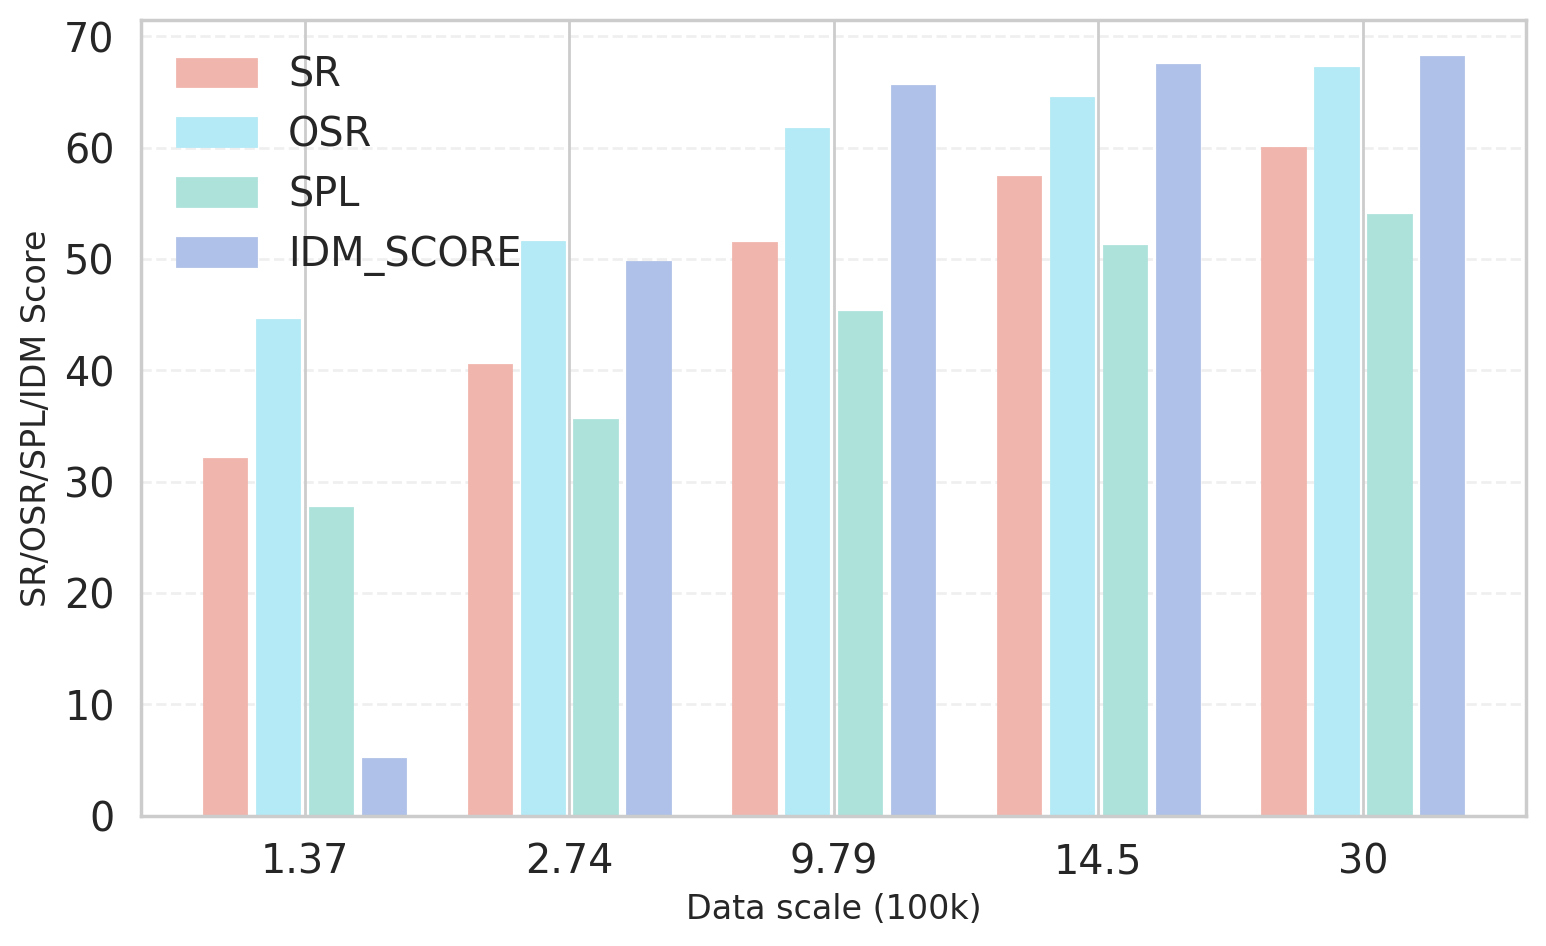

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x =         [1.37, 2.74, 9.79, 14.5, 30]
SR =        [32.0, 40.5, 51.4, 57.4, 60.0,]
OSR =       [44.5, 51.5, 61.7, 64.5, 67.2,]
SPL =       [27.6, 35.5, 45.2, 51.2, 54.0,]
IDM_SCORE = [5.09, 49.76, 65.56, 67.44, 68.11]
# 创建画布
# 颜色方案
colors = {
    "SR": "#F0B5AD",   # 鲜红橙
    "OSR": "#B3EAF6",  # 亮蓝青
    "SPL": "#ACE2DA",  # 绿青
    "IDM_SCORE": "#AFC1E8"    # 深蓝紫
}
def mix_colors(hex_list):
    rgb = np.mean([tuple(int(h[i:i+2], 16) for i in (1, 3, 5)) for h in hex_list], axis=0)
    return '#%02x%02x%02x' % tuple(int(v) for v in rgb)

mix_color = mix_colors([colors["SR"], colors["OSR"], colors["SPL"], colors["IDM_SCORE"]])
# 创建画布
def blend_with_white(hex_color, blend_factor):
    """
    blend_factor: 0 -> original color
                  1 -> pure white
    """
    rgb = np.array([int(hex_color[i:i+2], 16) for i in (1, 3, 5)])
    white = np.array([255, 255, 255])
    blended = (1 - blend_factor) * rgb + blend_factor * white
    return '#%02x%02x%02x' % tuple(blended.astype(int))

# Bar positions
x_pos = np.arange(len(x))
width = 0.2

plt.figure(figsize=(8, 5))

# Create gradient effect (lighter for larger x index)
blend_factors = np.linspace(0.0, 0.5, len(x))

for i in range(len(x)):
    plt.bar(x_pos[i] - 1.5*width, SR[i], width*0.8,
            color=colors["SR"], edgecolor=colors["SR"], linewidth=1)
    plt.bar(x_pos[i] - 0.5*width, OSR[i], width*0.8,
            color=colors["OSR"], edgecolor=colors["OSR"], linewidth=1)
    plt.bar(x_pos[i] + 0.5*width, SPL[i], width*0.8,
            color=colors["SPL"], edgecolor=colors["SPL"], linewidth=1)
    plt.bar(x_pos[i] + 1.5*width, IDM_SCORE[i], width*0.8,
            color=colors["IDM_SCORE"], edgecolor=colors["IDM_SCORE"], linewidth=1)

plt.xticks(x_pos, x)
plt.xlabel("Data scale (100k)", fontsize=12)
plt.ylabel("SR/OSR/SPL/IDM Score", fontsize=12)

plt.legend(["SR", "OSR", "SPL", "IDM_SCORE"], frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig("./fig/idm_score_performance-data_scale.pdf", format="pdf", dpi=200, bbox_inches='tight')
plt.show()


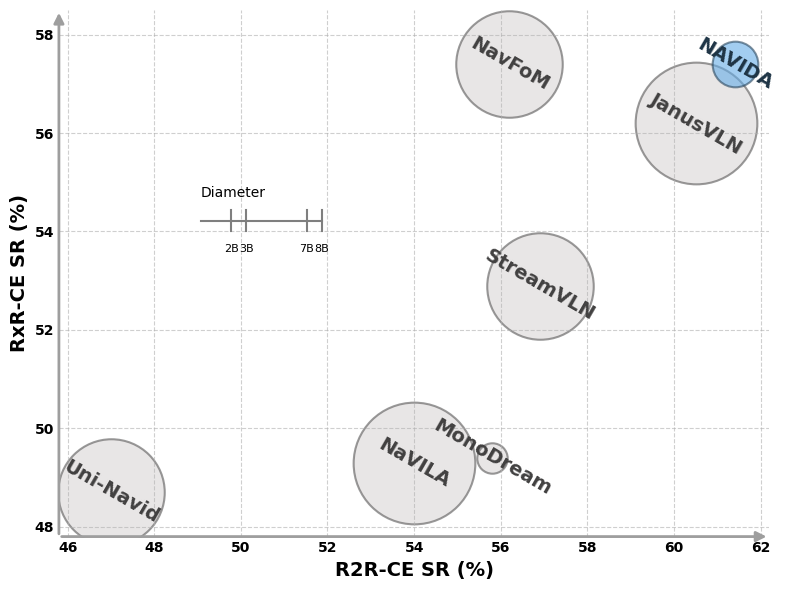

In [39]:

# Improved teaser-style bar chart (clean paper style)

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe

def darken_color(color, amount=0.55):
    """Return a darker shade of the given color."""
    c = np.array(mcolors.to_rgb(color))
    return tuple(c * (1 - amount))


# Data
x = ['NaVILA', 'MonoDream', 'Uni-Navid', 'StreamVLN', 'NavFoM', 'JanusVLN', 'NAVIDA']
SR = [ 54.0, 55.8, 47.0, 56.9, 56.2, 60.5, 61.4]
NE = [  5.22, 5.45, 5.58, 4.98, 5.01, 4.78, 4.32]
RXR_SR = [49.3, 49.4, 48.7,  52.9, 57.4, 56.2, 57.4]
model_size = np.array([8, 2, 7,  7, 7, 8, 3])
size_scale = 120
bubble_size = [item**2*size_scale for item in model_size]

# Soft pastel colors (last one highlighted slightly darker)
colors = ["#E9D8BC", "#C9E9C6", "#DBD1F0", "#D7E0F4", "#CEF2F6", "#E9BCA1", "#899092"]
colors = ["#DAD6D6"] * (len(x) - 1) + [ "#65ACE6"]

x_pos = np.arange(len(x))

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
})

fig, ax = plt.subplots(figsize=(8, 6))


for i, name in enumerate(x):
    edge_color = darken_color(colors[i], 0.6)
    ax.scatter(
        SR[i],
        RXR_SR[i],
        s=bubble_size[i],
        alpha=0.6,
        color=colors[i],
        edgecolors=edge_color,
        linewidth=1.5
    )
    text_color = darken_color(colors[i], 0.7)

    text = ax.text(SR[i], RXR_SR[i], name,
                ha='center', va='center', fontsize=14, weight='bold',color=text_color)
    text.set_rotation(-30)



# Axis formatting
ax.set_ylabel("RxR-CE SR (%)", fontsize=14, fontweight='bold')
# ax.set_xticks([])          # 去掉刻度
# ax.set_xticklabels([])     # 去掉刻度文字
ax.set_xlabel("R2R-CE SR (%)", fontsize=14, fontweight='bold')

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.set_ylim(47.8,58.5)
ax.set_xlim(45.8,62.2)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

# 画 x 轴箭头
ax.annotate(
    '', 
    xy=(xmax, ymin), 
    xytext=(xmin, ymin),
    arrowprops=dict(
        arrowstyle='-|>', 
        lw=2,
        color='#9E9E9E',
        mutation_scale=15
    )
)

# 画 y 轴箭头
ax.annotate(
    '', 
    xy=(xmin, ymax), 
    xytext=(xmin, ymin),
    arrowprops=dict(
        arrowstyle='-|>',
        lw=2,
        color='#9E9E9E',
        mutation_scale=15
    )
)


# Remove y tick marks but keep labels bold
ax.tick_params(axis='y', length=0)
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
ax.tick_params(axis='x', length=0)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

# Subtle horizontal grid
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', linestyle='--', alpha=0.6)


scale_models = [2, 3, 7, 8]

# 右下角位置（轴比例坐标 0~1）
x0 = 0.2
y0 = 0.6
width = 0.17

# 主横线
ax.plot([x0, x0+width], [y0, y0],
        transform=ax.transAxes,
        color='#7f7f7f', lw=1.5)

# 因为直径 ∝ B，所以线性映射
min_m = 0
max_m = max(scale_models)

for m in scale_models:
    pos = x0 + width * (m - min_m) / (max_m - min_m)
    
    # 刻度线
    ax.plot([pos, pos], [y0-0.02, y0+0.02],
            transform=ax.transAxes,
            color='#7f7f7f', lw=1.5)
    
    # 标签
    ax.text(pos, y0-0.045, f"{m}B",
            transform=ax.transAxes,
            ha='center', va='top',
            fontsize=8)

# 标题
ax.text(x0, y0+0.045, "Diameter",
        transform=ax.transAxes,
        fontsize=10, color="#000000")


plt.tight_layout()
plt.savefig("./fig/teaser_performance.png", format="png", dpi=200, bbox_inches='tight')
plt.show()

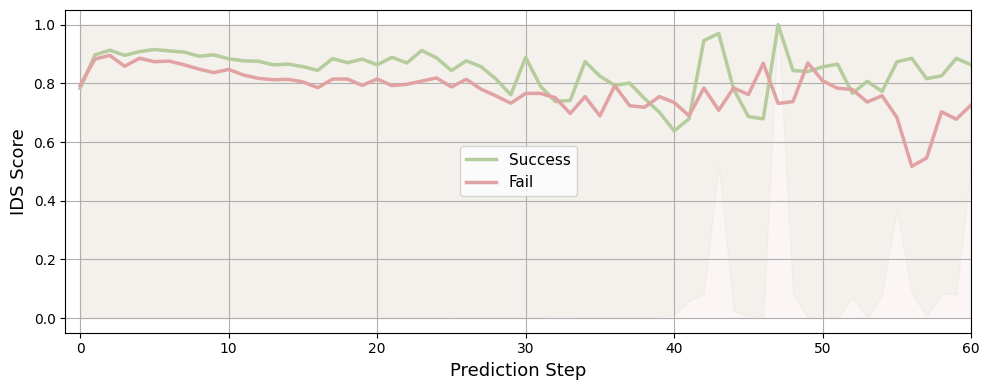

In [ ]:
import os
import numpy as np
import json
import math
import matplotlib.pylab as plt
import seaborn as sns
import pandas as pd

def check_inf_nan(value):
    if math.isinf(value) or math.isnan(value):
        return 0
    return value

def reliability_softmax(entropies, temp=0.2):
    # entropies: array_like
    scores = np.exp(np.array(entropies))
    return scores / (scores.sum() + 1e-12)


def flatten_results(idm_list, group_name):
    rows = []
    for traj_idx, traj_idm in enumerate(idm_list):
        for step_idx,  idm_values in enumerate(traj_idm):
            # if idm_values > 0.05:
                rows.append({
                        "Trajectory": traj_idx,
                        "Step": step_idx,
                        "IDM Score": check_inf_nan(idm_values),
                        "Group": group_name
                    })
    return pd.DataFrame(rows)


def process(path):
    jsons = os.listdir(os.path.join(path, 'log'))
    succ = 0
    spl = 0
    distance_to_goal = 0
    path_length = 0
    oracle_succ = 0

    success_idm = []
    fail_idm = []

    for j in jsons[:]:
        with open(os.path.join(path, 'log', j)) as f:
            try:
                data = json.load(f)
                succ += check_inf_nan(int(data['success']))
                spl += check_inf_nan(data['spl'])
                distance_to_goal += check_inf_nan(data['distance_to_goal'])
                oracle_succ += check_inf_nan(int(data['oracle_success']))
                path_length += data['path_length']
                idm_score = data['idm_score']
                if check_inf_nan(int(data['success'])) > 0:
                    success_idm.append(idm_score)
                else:
                    fail_idm.append(idm_score)
                
            except:
                print(j)

    df_success = flatten_results(success_idm, "Success")
    df_fail = flatten_results(fail_idm, "Fail")

    # 合并
    df_all = pd.concat([df_success, df_fail], ignore_index=True)

    # sns.set(style="whitegrid", font_scale=1.3, rc={"figure.dpi":200})

    plt.figure(figsize=(10,4))


    # 只取前60步
    df_plot = df_all[df_all["Step"] <= 60]

    # 计算统计量
    df_stats = (
        df_plot
        .groupby(["Step", "Group"])["IDM Score"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )


    colors = {
        "Success": "#B5CC9D",
        "Fail": "#E0A2A2"
    }

    for group in ["Success", "Fail"]:
        sub = df_stats[df_stats["Group"] == group]
        
        x = sub["Step"].to_numpy(dtype=float)
        y_mean = sub["mean"].to_numpy(dtype=float)
        y_min = sub["min"].to_numpy(dtype=float)
        y_max = sub["max"].to_numpy(dtype=float)
        
        # 画范围阴影（浅色）
        plt.fill_between(
            x,
            y_min,
            y_max,
            color=colors[group],
            alpha=0.1
        )
    
        # 画均值主线（深色）
        plt.plot(
            x,
            y_mean,
            color=colors[group],
            linewidth=2.5,
            label=group
        )




    plt.xlabel("Prediction Step", fontsize=13)
    plt.ylabel("IDS Score", fontsize=13)
    plt.legend(fontsize=11)
    plt.grid(True)
    # xticks = plt.xticks()[0]   # 获取当前刻度位置
    # step = 1                   # 每隔5个step显示一个标签
    # plt.xticks(xticks[::step], labels=[int(i) for i in xticks[::step]])
    plt.xlim(-1,60)
    plt.tight_layout()
    plt.savefig("./fig/idm_score.pdf", format="pdf", dpi=200, bbox_inches='tight')
    plt.show()

path = '/nvme-ssd1/zwy/navida/eval_log_with_idm/navida_best'
# path = "/nvme-ssd1/zwy/navida/eval_log_with_idm/Qwen2.5-VL_3B_sft_r2r_rxr_and_r2r_dagger_double_mix_task"
# path = "/nvme-ssd1/zwy/navida/eval_log_with_idm/navida_qwen2_5_vl_3b_train_on_mix_data_wo_rxr"
# path = "/nvme-ssd1/zwy/navida/eval_log_with_idm/Qwen2.5-VL_3B_sft_r2r_baseline"
process(path)



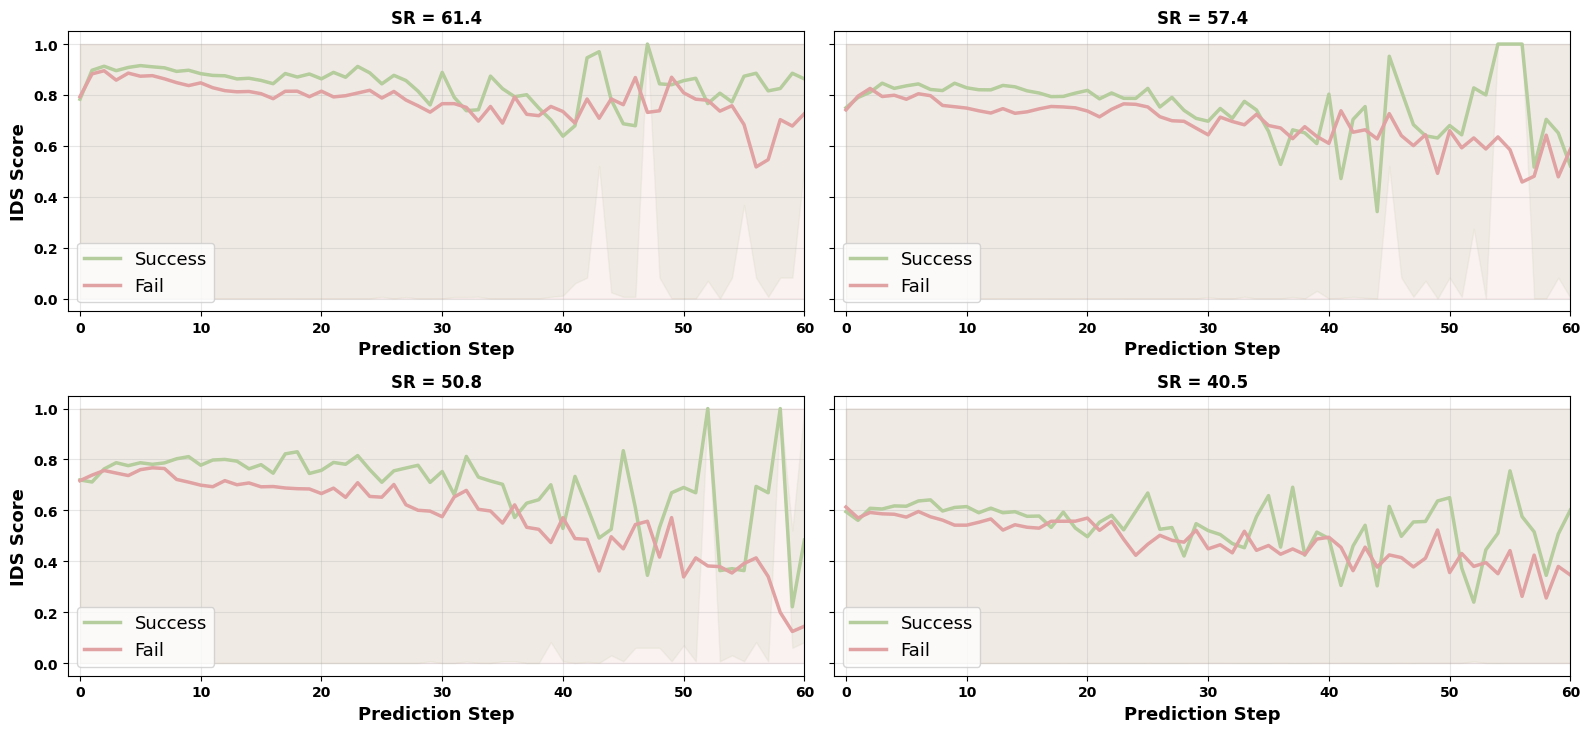

In [17]:
import os
import numpy as np
import json
import math
import matplotlib.pyplot as plt
import pandas as pd
import math as m

# =========================
# Utils
# =========================
def check_inf_nan(value):
    if math.isinf(value) or math.isnan(value):
        return 0
    return value


def flatten_results(idm_list, group_name):
    rows = []
    for traj_idx, traj_idm in enumerate(idm_list):
        for step_idx, idm_values in enumerate(traj_idm):
            rows.append({
                "Trajectory": traj_idx,
                "Step": step_idx,
                "IDM Score": check_inf_nan(idm_values),
                "Group": group_name
            })
    return pd.DataFrame(rows)


# =========================
# 读取数据
# =========================
def load_and_prepare(path):

    jsons = os.listdir(os.path.join(path, 'log'))

    success_idm = []
    fail_idm = []

    for j in jsons:
        with open(os.path.join(path, 'log', j)) as f:
            try:
                data = json.load(f)
                idm_score = data['idm_score']

                if check_inf_nan(int(data['success'])) > 0:
                    success_idm.append(idm_score)
                else:
                    fail_idm.append(idm_score)

            except:
                print(j)

    df_success = flatten_results(success_idm, "Success")
    df_fail = flatten_results(fail_idm, "Fail")

    df_all = pd.concat([df_success, df_fail], ignore_index=True)
    df_plot = df_all[df_all["Step"] <= 60]

    df_stats = (
        df_plot
        .groupby(["Step", "Group"])["IDM Score"]
        .agg(["mean", "min", "max"])
        .reset_index()
    )

    return df_stats


# =========================
# 主函数（两行布局）
# =========================
def process(path_list, sr_list):

    n = len(path_list)

    rows = 2
    cols = m.ceil(n / rows)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(8*cols, 4*rows),
        sharey=True
    )

    axes = np.array(axes).reshape(-1)  # 拉平成一维方便索引

    colors = {
        "Success": "#B5CC9D",
        "Fail": "#E0A2A2"
    }

    for idx, path in enumerate(path_list):

        ax = axes[idx]
        df_stats = load_and_prepare(path)

        for group in ["Success", "Fail"]:
            sub = df_stats[df_stats["Group"] == group]

            x = sub["Step"].to_numpy(dtype=float)
            y_mean = sub["mean"].to_numpy(dtype=float)
            y_min = sub["min"].to_numpy(dtype=float)
            y_max = sub["max"].to_numpy(dtype=float)

            ax.fill_between(
                x,
                y_min,
                y_max,
                color=colors[group],
                alpha=0.15
            )

            ax.plot(
                x,
                y_mean,
                color=colors[group],
                linewidth=2.5,
                label=group
            )
            ax.legend(
                fontsize=13,
                loc="lower left",
            )

        ax.set_xlim(-1, 60)
        # ax.set_ylim(0.15,1)
        ax.set_title(f"SR = {sr_list[idx]}", fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3)
        # ax.tick_params(axis='y', length=0)
        for label in ax.get_yticklabels():
            label.set_fontweight('bold')
        # ax.tick_params(axis='x', length=0)
        for label in ax.get_xticklabels():
            label.set_fontweight('bold')

        if idx % cols == 0:
            ax.set_ylabel("IDS Score", fontsize=13, fontweight='bold')

        ax.set_xlabel("Prediction Step", fontsize=13, fontweight='bold')

    # 删除多余空子图
    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    # 全局 legend
    # handles, labels = axes[0].get_legend_handles_labels()
    # fig.legend(
    #     handles,
    #     labels,
    #     loc="upper center",
    #     ncol=2,
    #     fontsize=15,
    #     frameon=False
    # )

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.savefig("./fig/idm_score.pdf",
                format="pdf",
                dpi=300,
                bbox_inches='tight')
    plt.show()


# =========================
# 路径
# =========================
path_list = [
    '/nvme-ssd1/zwy/navida/eval_log_with_idm/navida_best',
    "/nvme-ssd1/zwy/navida/eval_log_with_idm/Qwen2.5-VL_3B_sft_r2r_rxr_and_r2r_dagger_double_mix_task",
    "/nvme-ssd1/zwy/navida/eval_log_with_idm/navida_qwen2_5_vl_3b_train_on_mix_data_wo_rxr",
    "/nvme-ssd1/zwy/navida/eval_log_with_idm/navida_qwen2_5_vl_3b_train_on_r2r_mix_data_wo_dagger",
    # "/nvme-ssd1/zwy/navida/eval_log_with_idm/Qwen2.5-VL_3B_sft_r2r_baseline",
]
sr_list = [61.4, 57.4, 50.8, 40.5]

process(path_list, sr_list)